# Detecting pneumonia in chest X-rays: CNN from scratch vs ResNet18

This is a follow-up to my butterfly project. There I compared a CNN trained from scratch with a pretrained ResNet18. Here I run the same kind of comparison on chest X-rays, where the details matter more.

Three things I want to do differently this time:
1. Judge the models with AUROC, sensitivity and specificity, not just accuracy.
2. Deal with class imbalance (I'm checking the class counts below).
3. Look at Grad-CAM heatmaps to see what the model is actually looking at.

The three models:
1. A small CNN trained from scratch
2. ResNet18 with a frozen backbone
3. ResNet18 with the last block (layer4) fine-tuned

This is a learning project, not a clinical tool.

In [ ]:
# imports
!pip install -q medmnist
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader
from torchvision import transforms, models
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from medmnist import PneumoniaMNIST

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device)

torch.manual_seed(42)
np.random.seed(42)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 7.3 MB/s eta 0:00:00
Using cuda


## Settings
I keep the main settings in one place so they are easy to change.

In [ ]:
# settings
epochs_cnn = 15
epochs_frozen = 10
epochs_finetune = 10
lr_cnn = 0.001
lr_frozen = 0.001
lr_finetune = 0.0001
batch_size = 32

## Data
I'm using PneumoniaMNIST from MedMNIST. It is a chest X-ray dataset of children (label 0 = normal, 1 = pneumonia) that comes with an official train / validation / test split. I load it at 224x224 so it works with ResNet18.

The X-rays are grayscale, so I copy the one channel into three channels. The training images get a small random rotation. I'm not flipping images left to right, because the heart sits on one side of the body and a flipped X-ray would not look like a real one.

In [ ]:
# data import
size = 224
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
test_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

train_data = PneumoniaMNIST(split="train", transform=train_tf, download=True, size=size)
val_data = PneumoniaMNIST(split="val", transform=test_tf, download=True, size=size)
test_data = PneumoniaMNIST(split="test", transform=test_tf, download=True, size=size)
print("train", len(train_data), "val", len(val_data), "test", len(test_data))

100%|██████████| 214M/214M [00:32<00:00, 6.52MB/s]


train 4708 val 524 test 624


## Exploring the data
First the class counts in each split, then a few example images.

In [ ]:
# class counts
for name, data in [("train", train_data), ("val", val_data), ("test", test_data)]:
    labels = data.labels.flatten()
    print(name, "normal:", (labels == 0).sum(), "pneumonia:", (labels == 1).sum())

train normal: 1214 pneumonia: 3494
val normal: 135 pneumonia: 389
test normal: 234 pneumonia: 390


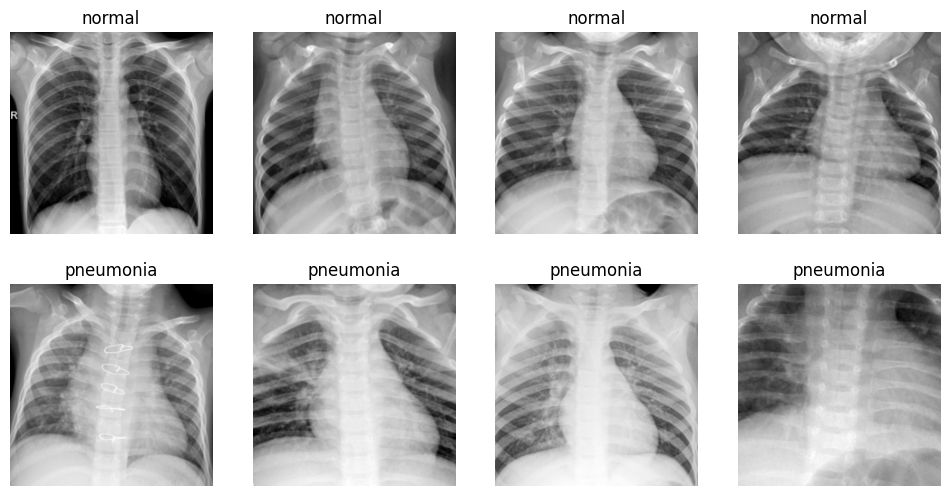

In [ ]:
# sample images (no transforms, so they look like the originals)
raw_data = PneumoniaMNIST(split="train", download=True, size=size)
raw_labels = raw_data.labels.flatten()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, label in enumerate([0, 1]):
    idxs = np.where(raw_labels == label)[0][:4]
    for col, i in enumerate(idxs):
        img, _ = raw_data[i]
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title("normal" if label == 0 else "pneumonia")
        axes[row, col].axis("off")
plt.show()

## Class imbalance
If one class has a lot more images, a model can score well by leaning toward that class. To handle this I give the loss function a weight for each class, so mistakes on the smaller class count more. Later I train one model without these weights to see what they change.

In [ ]:
# data loaders and class weights
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size)
test_loader = DataLoader(test_data, batch_size=batch_size)

train_labels = train_data.labels.flatten()
n_normal = (train_labels == 0).sum()
n_pneumonia = (train_labels == 1).sum()
total = len(train_labels)

class_weights = torch.tensor([total / (2 * n_normal), total / (2 * n_pneumonia)], dtype=torch.float32).to(device)
print("class weights (normal, pneumonia):", class_weights)

class weights (normal, pneumonia): tensor([1.9390, 0.6737], device='cuda:0')


## Models
Model 1 is a small CNN with four conv blocks. Models 2 and 3 are both a pretrained ResNet18 with a new final layer that has 2 outputs. In model 2 the whole backbone is frozen and only the new layer learns. In model 3 I also let layer4 (the last block) learn.

In [ ]:
# model 1: cnn from scratch
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        # 224 -> 112 -> 56 -> 28 -> 14
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(64 * 14 * 14, 2),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# model 2: resnet18 with frozen backbone
def make_frozen_resnet():
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for param in model.parameters():
        param.requires_grad = False
    model.fc = nn.Linear(512, 2)
    return model


# model 3: resnet18 with layer4 fine-tuned
def make_finetuned_resnet():
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for param in model.parameters():
        param.requires_grad = False
    for param in model.layer4.parameters():
        param.requires_grad = True
    model.fc = nn.Linear(512, 2)
    return model

## Training and evaluation helpers
`get_probs` gives the predicted probability of pneumonia for every image in a loader. The training function picks the epoch with the best validation AUROC, so I never use the test set to choose anything.

One detail: in a frozen layer the batch norm layers would still update their running averages in train mode. I switch those back to eval mode so frozen layers really stay frozen.

In [ ]:
# helper functions
def get_probs(model, loader):
    model.eval()
    all_probs = []
    all_labels = []
    with torch.no_grad():
        for images, labels in loader:
            out = model(images.to(device))
            probs = torch.softmax(out, dim=1)[:, 1]
            all_probs.append(probs.cpu().numpy())
            all_labels.append(labels.numpy().flatten())
    return np.concatenate(all_probs), np.concatenate(all_labels)


def train_model(model, name, epochs, lr, use_weights=True):
    model = model.to(device)
    if use_weights:
        loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    else:
        loss_fn = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = Adam(params, lr=lr)

    best_auc = 0
    best_state = None
    val_aucs = []

    for epoch in range(epochs):
        model.train()
        # keep batch norm layers eval if they are frozen
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
                m.eval()

        total_loss = 0
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.flatten().long().to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(images), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        probs, val_labels = get_probs(model, val_loader)
        val_auc = roc_auc_score(val_labels, probs)
        val_aucs.append(val_auc)
        print(name, "epoch", epoch + 1, "loss", round(total_loss / len(train_loader), 4), "val auc", round(val_auc, 4))

        if val_auc > best_auc:
            best_auc = val_auc
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, val_aucs


def get_metrics(labels, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    accuracy = (tp + tn) / len(labels)
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    return accuracy, sensitivity, specificity


def auc_confidence_interval(labels, probs, n_boot=1000):
    # bootstrap: resample the test set with replacement and recompute auc
    rng = np.random.default_rng(42)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(labels), len(labels))
        if len(set(labels[idx])) < 2:
            continue
        aucs.append(roc_auc_score(labels[idx], probs[idx]))
    return np.percentile(aucs, [2.5, 97.5])

## Model 1: CNN from scratch

In [ ]:
cnn_model, cnn_val_aucs = train_model(SimpleCNN(), "cnn", epochs_cnn, lr_cnn)

cnn epoch 1 loss 0.2422 val auc 0.9903
cnn epoch 2 loss 0.1476 val auc 0.9907
cnn epoch 3 loss 0.1417 val auc 0.9927
cnn epoch 4 loss 0.1207 val auc 0.9942
cnn epoch 5 loss 0.1049 val auc 0.9957
cnn epoch 6 loss 0.0985 val auc 0.9952
cnn epoch 7 loss 0.0855 val auc 0.9969
cnn epoch 8 loss 0.087 val auc 0.9962
cnn epoch 9 loss 0.0804 val auc 0.9966
cnn epoch 10 loss 0.085 val auc 0.9957
cnn epoch 11 loss 0.0772 val auc 0.9961
cnn epoch 12 loss 0.0799 val auc 0.9957
cnn epoch 13 loss 0.0692 val auc 0.9936
cnn epoch 14 loss 0.0682 val auc 0.9959
cnn epoch 15 loss 0.065 val auc 0.9962


## Model 2: ResNet18, frozen backbone

In [ ]:
frozen_model, frozen_val_aucs = train_model(make_frozen_resnet(), "frozen", epochs_frozen, lr_frozen)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


frozen epoch 1 loss 0.266 val auc 0.9731
frozen epoch 2 loss 0.1626 val auc 0.9805
frozen epoch 3 loss 0.1375 val auc 0.985
frozen epoch 4 loss 0.1358 val auc 0.9878
frozen epoch 5 loss 0.1193 val auc 0.9884
frozen epoch 6 loss 0.1172 val auc 0.9893
frozen epoch 7 loss 0.1071 val auc 0.9905
frozen epoch 8 loss 0.1093 val auc 0.9908
frozen epoch 9 loss 0.1042 val auc 0.9911
frozen epoch 10 loss 0.103 val auc 0.9916


## Model 3: ResNet18, layer4 fine-tuned
I use a smaller learning rate here because I'm changing pretrained weights.

In [ ]:
finetuned_model, finetuned_val_aucs = train_model(make_finetuned_resnet(), "finetuned", epochs_finetune, lr_finetune)

finetuned epoch 1 loss 0.1322 val auc 0.9983
finetuned epoch 2 loss 0.0699 val auc 0.9989
finetuned epoch 3 loss 0.0516 val auc 0.9994
finetuned epoch 4 loss 0.043 val auc 0.9991
finetuned epoch 5 loss 0.03 val auc 0.9995
finetuned epoch 6 loss 0.0202 val auc 0.9995
finetuned epoch 7 loss 0.0234 val auc 0.9991
finetuned epoch 8 loss 0.0194 val auc 0.9995
finetuned epoch 9 loss 0.0175 val auc 0.9993
finetuned epoch 10 loss 0.0185 val auc 0.9992


## Training curves
Validation AUROC after each epoch.

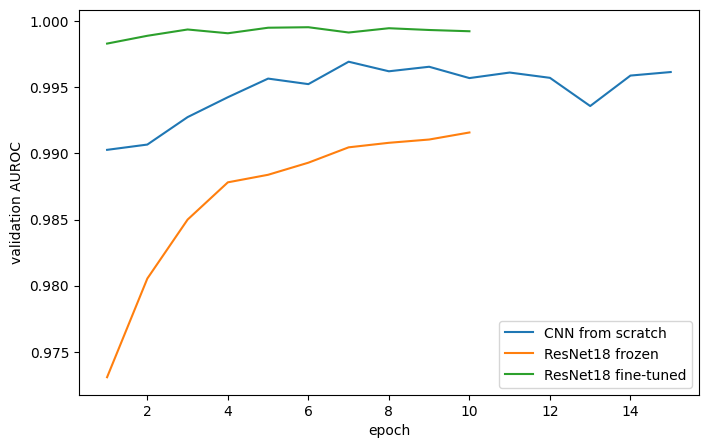

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cnn_val_aucs) + 1), cnn_val_aucs, label="CNN from scratch")
plt.plot(range(1, len(frozen_val_aucs) + 1), frozen_val_aucs, label="ResNet18 frozen")
plt.plot(range(1, len(finetuned_val_aucs) + 1), finetuned_val_aucs, label="ResNet18 fine-tuned")
plt.xlabel("epoch")
plt.ylabel("validation AUROC")
plt.legend()
plt.show()

## Test results
I only look at the test set now, after training is finished. The test set is small, so I also give a 95% bootstrap confidence interval for the AUROC. Accuracy, sensitivity and specificity use a threshold of 0.5. Sensitivity is the share of pneumonia cases the model catches. Specificity is the share of normal X-rays it correctly calls normal.

In [ ]:
# test results
models_to_test = [
    ("CNN from scratch", cnn_model),
    ("ResNet18 frozen", frozen_model),
    ("ResNet18 fine-tuned", finetuned_model),
]

rows = []
test_probs = {}
for name, model in models_to_test:
    probs, test_labels = get_probs(model, test_loader)
    test_probs[name] = probs
    auc = roc_auc_score(test_labels, probs)
    low, high = auc_confidence_interval(test_labels, probs)
    acc, sens, spec = get_metrics(test_labels, probs)
    rows.append({
        "model": name,
        "auroc": round(auc, 3),
        "auroc 95% ci": str(round(low, 3)) + " to " + str(round(high, 3)),
        "accuracy": round(acc, 3),
        "sensitivity": round(sens, 3),
        "specificity": round(spec, 3),
    })

results = pd.DataFrame(rows)
results

,model,auroc,auroc 95% ci,accuracy,sensitivity,specificity
0,CNN from scratch,0.934,0.908 to 0.956,0.877,0.985,0.697
1,ResNet18 frozen,0.983,0.974 to 0.99,0.931,0.982,0.846
2,ResNet18 fine-tuned,0.981,0.972 to 0.989,0.913,0.992,0.782


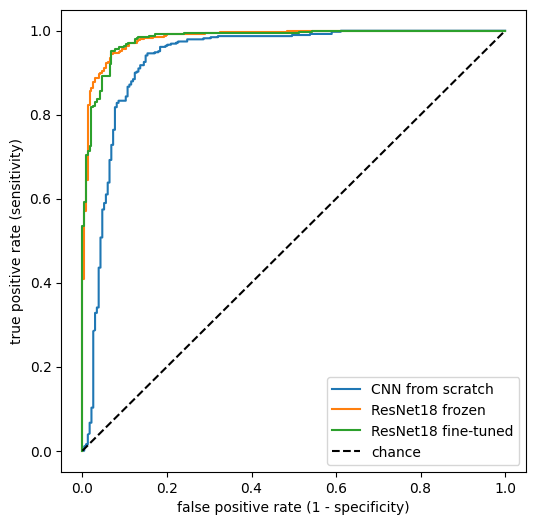

In [ ]:
# roc curves on the test set
plt.figure(figsize=(6, 6))
for name, probs in test_probs.items():
    fpr, tpr, _ = roc_curve(test_labels, probs)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="chance")
plt.xlabel("false positive rate (1 - specificity)")
plt.ylabel("true positive rate (sensitivity)")
plt.legend()
plt.show()

## What do the class weights change?
I train the fine-tuned model again with plain, unweighted loss and compare sensitivity and specificity.

In [ ]:
noweight_model, _ = train_model(make_finetuned_resnet(), "no weights", epochs_finetune, lr_finetune, use_weights=False)

probs, _ = get_probs(noweight_model, test_loader)
acc, sens, spec = get_metrics(test_labels, probs)
print("no class weights: auroc", round(roc_auc_score(test_labels, probs), 3), "sensitivity", round(sens, 3), "specificity", round(spec, 3))

acc, sens, spec = get_metrics(test_labels, test_probs["ResNet18 fine-tuned"])
print("with class weights: auroc", round(roc_auc_score(test_labels, test_probs["ResNet18 fine-tuned"]), 3), "sensitivity", round(sens, 3), "specificity", round(spec, 3))

no weights epoch 1 loss 0.1089 val auc 0.9978
no weights epoch 2 loss 0.0561 val auc 0.9993
no weights epoch 3 loss 0.0494 val auc 0.9993
no weights epoch 4 loss 0.0318 val auc 0.9991
no weights epoch 5 loss 0.0181 val auc 0.9997
no weights epoch 6 loss 0.0257 val auc 0.9991
no weights epoch 7 loss 0.0232 val auc 0.9997
no weights epoch 8 loss 0.0192 val auc 0.9996
no weights epoch 9 loss 0.012 val auc 0.9995
no weights epoch 10 loss 0.0135 val auc 0.9995
no class weights: auroc 0.988 sensitivity 1.0 specificity 0.65
with class weights: auroc 0.981 sensitivity 0.992 specificity 0.782


## Choosing a threshold
For a screening tool, missing a sick patient is worse than a false alarm. So instead of using 0.5, I pick the highest threshold on the validation set that still catches at least 95% of pneumonia cases, then check what that does on the test set.

In [ ]:
# threshold chosen on the validation set only
val_probs, val_labels = get_probs(finetuned_model, val_loader)
fpr, tpr, thresholds = roc_curve(val_labels, val_probs)
idx = np.where(tpr >= 0.95)[0][0]
chosen_threshold = thresholds[idx]
print("chosen threshold:", round(float(chosen_threshold), 3))

acc, sens, spec = get_metrics(test_labels, test_probs["ResNet18 fine-tuned"], threshold=chosen_threshold)
print("test accuracy", round(acc, 3), "sensitivity", round(sens, 3), "specificity", round(spec, 3))

chosen threshold: 0.683
test accuracy 0.931 sensitivity 0.987 specificity 0.838


## Grad-CAM: what is the model looking at?
Grad-CAM shows which parts of the image pushed the model toward its answer. It uses the output of layer4 and the gradients that flow back to it. I look at a few correct pneumonia predictions and a few mistakes. If the model is looking at the lungs, that is a good sign. If it is looking at a letter marker or the corner of the image, that is a warning.

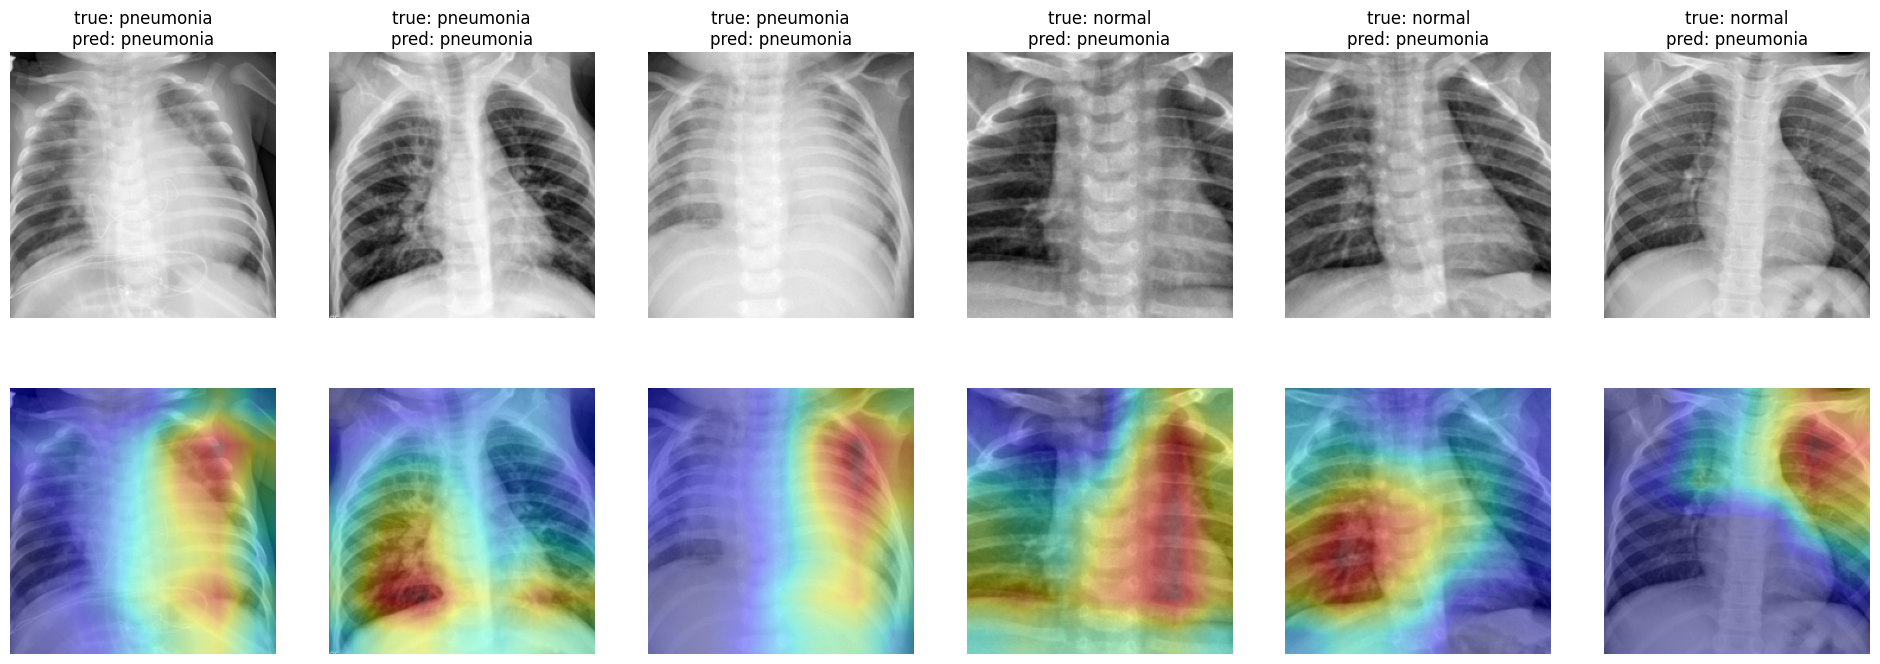

In [ ]:
# grad-cam for the fine-tuned resnet
def grad_cam(model, image, target_class):
    feats = []
    grads = []

    def forward_hook(module, inputs, output):
        feats.append(output)
        output.register_hook(lambda g: grads.append(g))

    handle = model.layer4.register_forward_hook(forward_hook)
    model.eval()
    out = model(image.unsqueeze(0).to(device))
    model.zero_grad()
    out[0, target_class].backward()
    handle.remove()

    weights = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = (weights * feats[0]).sum(dim=1, keepdim=True)
    cam = F.relu(cam)
    cam = F.interpolate(cam, size=(size, size), mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam


probs = test_probs["ResNet18 fine-tuned"]
preds = (probs >= 0.5).astype(int)
correct_pneumonia = np.where((test_labels == 1) & (preds == 1))[0][:3]
mistakes = np.where(test_labels != preds)[0][:3]
to_show = list(correct_pneumonia) + list(mistakes)

raw_test = PneumoniaMNIST(split="test", download=True, size=size)

fig, axes = plt.subplots(2, len(to_show), figsize=(4 * len(to_show), 8))
for col, i in enumerate(to_show):
    tensor_img, _ = test_data[i]
    cam = grad_cam(finetuned_model, tensor_img, target_class=int(preds[i]))
    raw_img, _ = raw_test[i]
    title = "true: " + ("pneumonia" if test_labels[i] == 1 else "normal") + "\npred: " + ("pneumonia" if preds[i] == 1 else "normal")
    axes[0, col].imshow(raw_img, cmap="gray")
    axes[0, col].set_title(title)
    axes[0, col].axis("off")
    axes[1, col].imshow(raw_img, cmap="gray")
    axes[1, col].imshow(cam, cmap="jet", alpha=0.4)
    axes[1, col].axis("off")
plt.show()

In [ ]:
# save the results table
results.to_csv("results.csv", index=False)